In [1]:
import os
import sys
import numpy as np
import scipy
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import Plot_Background,plot_quivers,CircleCalc,ImageS
from utils.raytracing import calculate_source_position


In [ ]:
GRMHD_cut_150=np.genfromtxt("data/GRMHD_cut_150",delimiter=',')
GRMHD_cut_150.shape

In [2]:
GRMHD_cut = np.genfromtxt("data/GRMHD_cut", delimiter=',')
GRMHD_cut.shape

(17932640, 8)

In [ ]:
resolution=150

In [6]:
block,pixel, r, theta, phi, t,alpha,alpha_amp=GRMHD_cut.T
block = block.astype(int)
pixel = pixel.astype(int)
# bp_pair = np.array([[block[i],pixel[i]] for i in range(len(block))])
bp_pair = np.column_stack((block, pixel))
bp_pair_unique = np.unique(bp_pair.astype(int), axis=0)

indices_bp = np.zeros((block.max()+1, pixel.max()+1), dtype=int) -1 # Assuming block and pixel are both in [0, resolution)

# fill indices_bp: at (b, p) store its index in bp_pair_unique
# for idx, (b, p) in enumerate(bp_pair_unique.astype(int)):
#     if 0 <= b < block.max()+1 and 0 <= p < pixel.max()+1:
#         indices_bp[b, p] = idx

indices_bp[bp_pair_unique[:, 0], bp_pair_unique[:, 1]] = np.arange(len(bp_pair_unique))

bp_indices = indices_bp[block, pixel]
# bp_indices = [indices_bp[int(block[i]), int(pixel[i])] for i in range(len(block))]

In [5]:
r_bp = [[[] for j in range(100)] for i in range(100)]
theta_bp = [[[] for j in range(100)] for i in range(100)]
phi_bp = [[[] for j in range(100)] for i in range(100)]
t_bp = [[[] for j in range(100)] for i in range(100)]
alpha_bp = [[[] for j in range(100)] for i in range(100)]
alpha_amp_bp = [[[] for j in range(100)] for i in range(100)]

for i in range(len(block)):
    b = int(block[i])
    p = int(pixel[i])
    if 0 <= b < 100 and 0 <= p < 100:
        idx = indices_bp[b, p]
        if idx != -1:
            r_bp[b][p].append(r[i])
            theta_bp[b][p].append(theta[i])
            phi_bp[b][p].append(phi[i])
            t_bp[b][p].append(t[i])
            alpha_bp[b][p].append(alpha[i])
            alpha_amp_bp[b][p].append(alpha_amp[i])

for b in range(100):
    for p in range(100):
        if len(r_bp[b][p]) > 0:
            r_bp[b][p] = np.array(r_bp[b][p])
            theta_bp[b][p] = np.array(theta_bp[b][p])
            phi_bp[b][p] = np.array(phi_bp[b][p])
            t_bp[b][p] = np.array(t_bp[b][p])
            alpha_bp[b][p] = np.array(alpha_bp[b][p])
            alpha_amp_bp[b][p] = np.array(alpha_amp_bp[b][p])

In [7]:
block_line = int(np.sqrt(np.unique(block).size))
pixel_line = int(np.sqrt(np.unique(pixel).size))
img_size = block_line * pixel_line

# 1. 转换 block/pixel → 图像像素坐标 (x, y)
b = block.astype(int)
p = pixel.astype(int)

bx = b // block_line
by = b % block_line
px = p // pixel_line
py = p % pixel_line

x = bx * pixel_line + px
y = by * pixel_line + py

# 2. 初始化以 (x, y) 为下标的存储结构
r_xy = [[[] for _ in range(img_size)] for _ in range(img_size)]
theta_xy = [[[] for _ in range(img_size)] for _ in range(img_size)]
phi_xy = [[[] for _ in range(img_size)] for _ in range(img_size)]
t_xy = [[[] for _ in range(img_size)] for _ in range(img_size)]
alpha_xy = [[[] for _ in range(img_size)] for _ in range(img_size)]
alpha_amp_xy = [[[] for _ in range(img_size)] for _ in range(img_size)]

# 3. 一次性把数据塞进去（矢量化思想：仍然是单循环，但不用复杂映射）
for i in range(len(x)):
    xi = x[i]
    yi = y[i]
    r_xy[xi][yi].append(r[i])
    theta_xy[xi][yi].append(theta[i])
    phi_xy[xi][yi].append(phi[i])
    t_xy[xi][yi].append(t[i])
    alpha_xy[xi][yi].append(alpha[i])
    alpha_amp_xy[xi][yi].append(alpha_amp[i])

# 4. 转成 numpy 数组
for xi in range(img_size):
    for yi in range(img_size):
        if len(r_xy[xi][yi]) > 0:
            r_xy[xi][yi] = np.array(r_xy[xi][yi])
            theta_xy[xi][yi] = np.array(theta_xy[xi][yi])
            phi_xy[xi][yi] = np.array(phi_xy[xi][yi])
            t_xy[xi][yi] = np.array(t_xy[xi][yi])
            alpha_xy[xi][yi] = np.array(alpha_xy[xi][yi])
            alpha_amp_xy[xi][yi] = np.array(alpha_amp_xy[xi][yi])

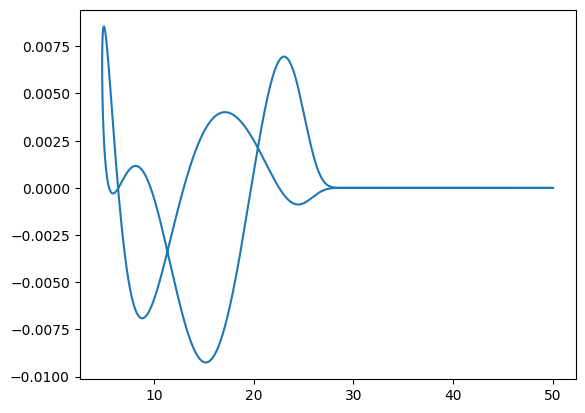

In [8]:
plt.plot(r_xy[40][40],alpha_xy[40][40])

In [28]:
# 初始化结果数组，默认值为 nan
r_at_theta_pi_2 = np.full((img_size, img_size), np.nan)
phi_at_theta_pi_2 = np.full((img_size, img_size), np.nan)
t_at_theta_pi_2 = np.full((img_size, img_size), np.nan)
alpha_amp_at_theta_pi_2 = np.full((img_size, img_size), np.nan)


# 遍历所有像素点
for xi in range(img_size):
    for yi in range(img_size):
        thetas = theta_xy[xi][yi]
        if len(thetas) > 0:
            diffs = thetas - np.pi/2
            # mask 中 True 表示 θ<π/2
            mask = diffs < 0
            if mask.any():
                # 找到最后一个 True 的索引
                last_idx_1 = np.where(mask)[0][-1]
                last_idx_2 = last_idx_1 + 1 if last_idx_1 + 1 < len(diffs) else last_idx_1
                diffs_1= np.abs(diffs[last_idx_1])
                diffs_2= np.abs(diffs[last_idx_2])
                r_at_theta_pi_2[xi, yi] = (r_xy[xi][yi][last_idx_1]*diffs_2+r_xy[xi][yi][last_idx_2]*diffs_1) / (diffs_1 + diffs_2)
                phi_at_theta_pi_2[xi, yi] = (phi_xy[xi][yi][last_idx_1]*diffs_2+phi_xy[xi][yi][last_idx_2]*diffs_1) / (diffs_1 + diffs_2)
                t_at_theta_pi_2[xi, yi] = (t_xy[xi][yi][last_idx_1]*diffs_2+t_xy[xi][yi][last_idx_2]*diffs_1) / (diffs_1 + diffs_2)
                alpha_amp_at_theta_pi_2[xi, yi] = (alpha_amp_xy[xi][yi][last_idx_1]*diffs_2+alpha_amp_xy[xi][yi][last_idx_2]*diffs_1) / (diffs_1 + diffs_2)


In [ ]:
np.save("data/r_coord.npy", r_at_theta_pi_2)
_axion_field_16=np.asarray([alpha_amp_at_theta_pi_2*np.cos(-phi_at_theta_pi_2+(1022.0+t_at_theta_pi_2)*0.29915625 + phase_index/8.0 * np.pi) for phase_index in range(16)])
_axion_field_16[np.isnan(_axion_field_16)] = 0.0  # 将 NaN 替换为 0.0
np.save("data/axion_field_coord_16.npy",_axion_field_16)

In [31]:
_axion_field_16=np.asarray([alpha_amp_at_theta_pi_2*np.cos(-phi_at_theta_pi_2+(1022.0+t_at_theta_pi_2)*0.29915625 + phase_index/8.0 * np.pi) for phase_index in range(16)])
_axion_field_16[np.isnan(_axion_field_16)] = 0.0  # 将 NaN 替换为 0.0
np.save("data/axion_field_coord_16.npy",_axion_field_16)

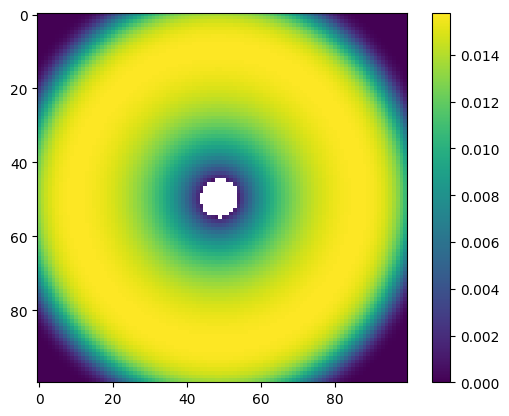

In [10]:
plt.imshow(alpha_amp_at_theta_pi_2)
plt.colorbar()

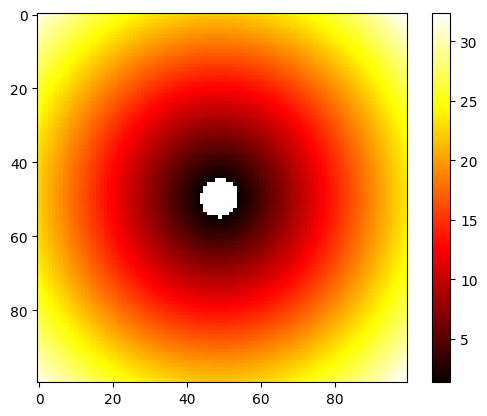

In [ ]:
plt.imshow(r_at_theta_pi_2, cmap='hot')
plt.colorbar()
# plt.clim(0.9,1.1)

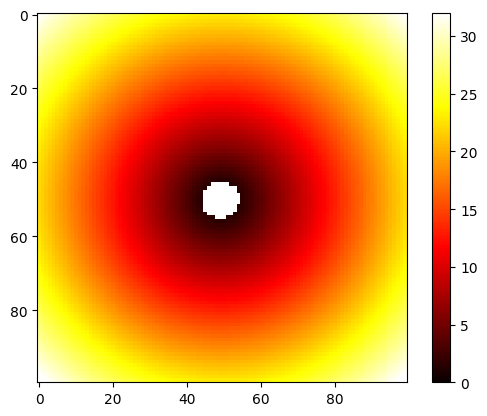

In [115]:
plt.imshow(r_s, cmap='hot', interpolation='nearest')
plt.colorbar()
plt.clim(0,32)

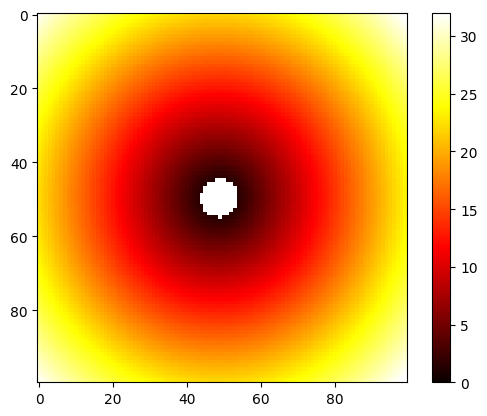

In [77]:
plt.imshow(r_at_theta_pi_2, cmap='hot', interpolation='nearest')
plt.colorbar()
plt.clim(0,32)

In [25]:
from functools import lru_cache

@lru_cache(maxsize=None)  # None 表示无限缓存
def _calculate_source_position(x,y):
    print("1")
    obs_rho = np.sqrt(x**2 + y**2)
    obs_phi = np.arctan2(x, y)  # 特别注意这个phi是和y轴的夹角，顺时针增大
    try: 
        return calculate_source_position(
            obs_rho=obs_rho,
            obs_phi=obs_phi,
            r_o=500,
            theta_o=17 / 180 * np.pi,
            a=-0.9375,
            M=1.0,
        )  # phi_s又是逆时针的)
    except Exception as e:
        print(e)
        return (200.,0.,0.)
_v_calculate_source_position = np.vectorize(_calculate_source_position)

In [26]:
x_coords = np.tile(np.linspace(49.5, -49.5, 100), (100, 1)) * 46.2262 / 99
y_coords = np.tile(np.linspace(49.5, -49.5, 100).reshape(100, 1), (1, 100)) * 46.2262 / 99
r_s,phi_s,t_s= _v_calculate_source_position(x_coords, y_coords)

1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/raytracing.py:164: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  G_phi_2, _ = quad(integrand_G_phi, theta_c, theta_o, -sign_theta)


1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/raytracing.py:187: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  I_t_1, _ = quad(integrand_I_t, r_s, r_c, sign_r)


1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/raytracing.py:193: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  _I_r = lambda _r_s: quad(integrand_I_r, _r_s, r_o, sign_r)[0] - G_theta


1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


In [30]:
_alpha_amp_max=0
for b in range(100):
    for p in range(100):
        if len(r_bp[b][p]) > 0:
            if np.max(alpha_amp_bp[b][p]) > _alpha_amp_max:
                _alpha_amp_max = np.max(alpha_amp_bp[b][p])
                _b, _p = b, p

print(f"Max alpha_amp at block {int(_b)}, pixel {int(_p)}: {_alpha_amp_max}")

Max alpha_amp at block 12, pixel 59: 0.015807
